# Corrigé — Bruit thermique sur une mesure de température par NTC

## Rappel de la donnée

Une résistance NTC est montée en diviseur de tension avec une résistance de pull-up, entre l'alimentation et la masse.
La tension $V_{out}$ est acquise par un ADC d'impédance d'entrée infinie.


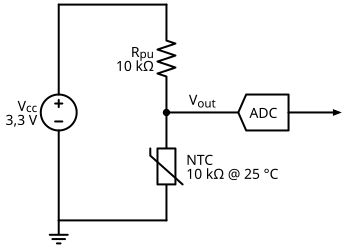

In [60]:
# Pour le fun, dessin d'un circuit électrique avec Python et schemdraw...

import schemdraw
import schemdraw.elements as elm
from schemdraw import dsp

schemdraw.use('svg')  # rendu vectoriel dans le notebook

with schemdraw.Drawing() as d:
    d.config(unit=3)
    # Source de tension, sur la hauteur des deux composants
    src = elm.SourceV().up().length(6).label('V$_{cc}$\n3,3 V')
    elm.Line().right().length(3)
    # Diviseur : pull-up puis NTC
    elm.Resistor().down().label('R$_{pu}$\n10 kΩ')
    noeud = elm.Dot()
    elm.Thermistor().down().label('NTC\n10 kΩ @ 25 °C', loc='bottom')
    # Retour à la source et masse
    elm.Line().left().tox(src.start)
    elm.Ground().at(src.start)
    # Sortie vers l'ADC
    elm.Line().right().at(noeud.center).length(2).label('V$_{out}$')
    adc = dsp.Adc().anchor('input').label('ADC')
    elm.Arrow().right().at(adc.out).length(1.5)


**Caractéristique de la NTC** ($T$ en Kelvin) :

$$ R_{ntc}(T) = R_{25}\exp\left(\beta\left(\frac{1}{T} - \frac{1}{T_{25}}\right)\right) $$

| Paramètre | Valeur |
|---|---|
| Résistance à 25 °C $R_{25}$ | 10 kΩ |
| Coefficient $\beta$ | 3965 K |
| Température de référence $T_{25}$ | 298 K |
| Tension d'alimentation $V_{cc}$ | 3.3 V |
| Résistance de pull-up $R_{pull}$ | 10 kΩ |
| Bande passante $\Delta f$ | 1000 Hz |
| Constante de Boltzmann $k_B$ | $1.381\times 10^{-23}$ J/K |

# Fonction de présentation

Ces fonctions aident à représenter les équations.

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import display, Math

# --- Outils d'affichage -------------------------------------------------
PREFIXES = [(1e9, 'G'), (1e6, 'M'), (1e3, 'k'), (1, ''), (1e-3, 'm'), (1e-6, r'\mu '), (1e-9, 'n')]

def fmt(x, unit='', prefix=True, sig=3, dec=None, pref=None):
    # Valeur avec préfixe SI (automatique ou imposé par pref) et 3 chiffres significatifs
    x = float(x)
    p = ''
    if pref is not None:
        f = dict((s, f) for f, s in PREFIXES)[pref]
        x, p = x / f, pref
    elif prefix and x != 0:
        for f, s in PREFIXES:
            if abs(x) >= 0.9995 * f:
                break
        x, p = x / f, s
    u = rf"\ \mathrm{{{p}{unit}}}" if (p or unit) else ''
    if dec is None and x != 0 and not (1e-3 <= abs(x) < 1e5):
        m, e = f"{x:.{sig-1}e}".split('e')
        return rf"{m} \cdot 10^{{{int(e)}}}{u}"
    if dec is None:
        dec = max(0, sig - 1 - int(np.floor(np.log10(abs(x))))) if x != 0 else 0
    return rf"{x:.{dec}f}{u}"

def show(name, value, unit='', **kw):
    # Affiche  nom = valeur unité
    display(Math(rf"{name} = {fmt(value, unit, **kw)}"))

def eq(lhs, expr):
    # Affiche  lhs = expression
    display(Math(rf"{lhs} = {sp.latex(expr)}"))

## Définitions

Ici on définit les symboles utiles ainsi que les valeurs numériques.

In [62]:
# Symboles
kB, T, R, dF = sp.symbols(r'k_B T R \Delta{}f')
R25, T25, beta = sp.symbols('R_{25} T_{25} beta')
Rp, Rn, Vcc = sp.symbols('R_{pull} R_{ntc} V_{cc}')

# Valeurs de l'énoncé
valeurs = {kB: 1.381e-23, dF: 1000, R25: 10e3, T25: 298.15, beta: 3965, Rp: 10e3, Vcc: 3.3}

T0 = 273.15          # 0 °C en Kelvin
T_C = 25             # point de fonctionnement [°C]
T_K = T0 + T_C       # point de fonctionnement [K]

##  Evolution de la température

On peut représenter l'évolution de la résistance à partir des définitions ci-dessus.

Text(0, 0.5, 'R_NTC [kohms]')

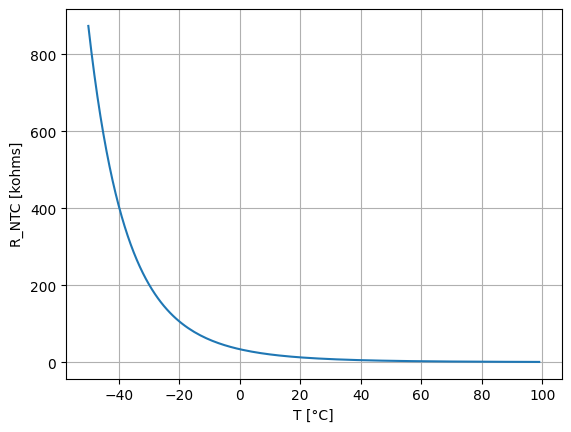

In [63]:
Rntc_T = R25 * sp.exp(beta * (1/T - 1/T25))

Tv=np.arange(-50,100,1)
Rv=sp.lambdify(T,Rntc_T.subs(valeurs), 'numpy')
plt.plot(Tv,Rv(Tv+T0)/1000)
plt.grid()
plt.xlabel("T [°C]")
plt.ylabel("R_NTC [kohms]")


Text(0, 0.5, 'U_out [V]')

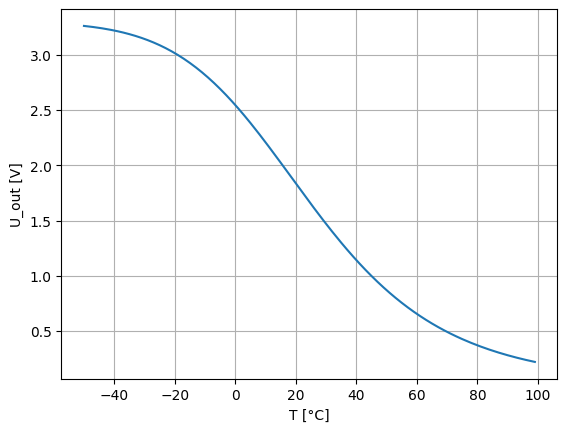

In [64]:
Uout=Vcc*Rn/(Rn+Rp)

U=sp.lambdify(Rn, Uout.subs(valeurs), 'numpy')

plt.plot(Tv,U(Rv(Tv+T0)))
plt.grid()
plt.xlabel("T [°C]")
plt.ylabel("U_out [V]")

## Partie 1 — Bruit de Johnson-Nyquist sur une résistance

### 1.1 Homogénéité

$e_n = \sqrt{4 k_B T R \Delta f}$ avec :

| Grandeur | Unité | Unités de base |
|---|---|---|
| $k_B$ | J/K | kg·m²·s⁻²·K⁻¹ |
| $T$ | K | K |
| $R$ | Ω = V/A | kg·m²·s⁻³·A⁻² |
| $\Delta f$ | Hz | s⁻¹ |

$k_B T R \Delta f$ : kg²·m⁴·s⁻⁶·A⁻² $=$ V², car V = W/A = kg·m²·s⁻³·A⁻¹. La racine est bien une tension.

### 1.2 Application numérique

In [65]:
e_n = sp.sqrt(4 * kB * T * R * dF)
eq('e_n(R,T)', e_n)

en_10k = e_n.subs(valeurs).subs({R: 10e3, T: T_K})
show(r'e_n(R = 10\ \mathrm{k\Omega},\ T = 25\ ^\circ\mathrm{C})', en_10k, 'V', pref=r'\mu ')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Le bruit thermique d'une résistance de 10 kΩ sur 1 kHz est de l'ordre de **quelques centaines de nV**, soit ≈ 0.4 µV.

## Partie 2 — Bruit combiné au point milieu du diviseur

### 2.1 Superposition

$V_{cc}$ est une source idéale, donc équivalente à la masse pour le bruit. Chaque source de bruit voit un diviseur formé par les deux résistances :

In [66]:
e_pull, e_ntc = sp.symbols(r'e_{n\,pull} e_{n\,ntc}')

v_pull = e_pull * Rn / (Rp + Rn)
v_ntc = e_ntc * Rp / (Rp + Rn)
eq('v_{pull}', v_pull)
eq('v_{ntc}', v_ntc)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 2.2 Somme quadratique

Les deux bruits sont **indépendants (non corrélés)** : on additionne les variances (puissances), pas les amplitudes.
On remplace $e_{n\,pull}^2 = 4k_BT\Delta f\,R_{pull}$ et $e_{n\,ntc}^2 = 4k_BT\Delta f\,R_{ntc}$ :

In [67]:
var_out = (v_pull**2 + v_ntc**2).subs({e_pull: e_n.subs(R, Rp), e_ntc: e_n.subs(R, Rn)})
print("Superposition des 2 sources de bruit pour la sortie :")
eq('e_{n,out}^2', sp.factor(sp.simplify(var_out)))

Req = Rp * Rn / (Rp + Rn)
e_out = e_n.subs(R, Req)
print("Expression de la résistance équivalente")
eq('R_{eq}', Req)
print("Bruit résultant de la résistance équivalente")
eq('e_{n,out}', e_out)

verif = sp.simplify(var_out - e_out**2) == 0
print("Vérification de l'identité des deux valeurs de bruit")
display(Math(r'e_{n,out}^2 - 4k_BT\Delta f\,R_{eq} = 0 \quad ' + (r'\checkmark' if verif else r'\times')))

Superposition des 2 sources de bruit pour la sortie :


<IPython.core.display.Math object>

Expression de la résistance équivalente


<IPython.core.display.Math object>

Bruit résultant de la résistance équivalente


<IPython.core.display.Math object>

Vérification de l'identité des deux valeurs de bruit


<IPython.core.display.Math object>

Le bruit au point milieu est celui d'une seule résistance $R_{eq} = R_{pull} \parallel R_{ntc}$.

### 2.3 Application numérique à 25 °C

In [68]:
Rntc_T = R25 * sp.exp(beta * (1/T - 1/T25))
eq('R_{ntc}(T)', Rntc_T)

Rntc_25 = Rntc_T.subs(valeurs).subs(T, T_K)
Req_25 = Req.subs(Rn, Rntc_25).subs(valeurs)
eout_25 = e_out.subs(Rn, Rntc_25).subs(valeurs).subs(T, T_K)

show(r'R_{ntc}(25\ ^\circ\mathrm{C})', Rntc_25, r'\Omega')
show('R_{eq}', Req_25, r'\Omega')
show('e_{n,out}', eout_25, 'V', pref=r'\mu ')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


## Partie 3 — De la tension bruitée à la température bruitée

### 3.1 Tension de sortie

In [69]:
Uout = Vcc * Rn / (Rp + Rn)
eq('U_{out}', Uout)
eq('U_{out}(T)', Uout.subs(Rn, Rntc_T))

Uout_25 = Uout.subs(Rn, Rntc_25).subs(valeurs)
show(r'U_{out}(25\ ^\circ\mathrm{C})', Uout_25, 'V')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 3.2 Sensibilité par dérivation en chaîne

$$ S(T) = \frac{dU_{out}}{dT} = \frac{dU_{out}}{dR_{ntc}} \cdot \frac{dR_{ntc}}{dT} $$

In [70]:
dU_dR = sp.simplify(sp.diff(Uout, Rn))
dR_dT = sp.diff(Rntc_T, T)
print("Expression des dérivées")
eq(r'\frac{dU_{out}}{dR_{ntc}}', dU_dR)
eq(r'\frac{dR_{ntc}}{dT}', dR_dT)

# Évaluation au point de fonctionnement : la dérivée du pont est prise en R_ntc (et non en R_eq)
S_pont = dU_dR.subs(Rn, Rntc_25).subs(valeurs)
S_ntc = dR_dT.subs(valeurs).subs(T, T_K)
S_25 = S_pont * S_ntc

print("Evaluation à 25°C")
show(r'\frac{dU_{out}}{dR_{ntc}}(25\ ^\circ\mathrm{C})', S_pont, r'V/\Omega')
show(r'\frac{dR_{ntc}}{dT}(25\ ^\circ\mathrm{C})', S_ntc, r'\Omega/K')
show(r'S(25\ ^\circ\mathrm{C})', S_25, 'V/K')

Expression des dérivées


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Evaluation à 25°C


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

La sensibilité est négative : quand la température augmente, $R_{ntc}$ diminue et $U_{out}$ aussi.

### 3.3 Du bruit de tension au bruit de température

Pour une petite variation, $\delta U = S\,\delta T$. Le bruit de tension se traduit donc par une incertitude sur la température :

$$ \sigma_T(T) = \frac{e_{n,out}(T)}{|S(T)|} $$

### 3.4 Application numérique et comparaison

In [71]:
sigma_T = eout_25 / abs(S_25)
print("Influence du bruit à 25 °C")
show(r'\sigma_T(25\ ^\circ\mathrm{C})', sigma_T, 'K')

# Comparaison : quantification d'un ADC 12 bits avec V_ref = V_cc
N = 12
LSB = valeurs[Vcc] / 2**N
dT_LSB = LSB / abs(S_25)
print("Un LSB du convertisseur AD équivaut à...")
show(r'\mathrm{LSB}_{12\,bits}', LSB, 'V')
show(r'\Delta T_{LSB} = \mathrm{LSB} / |S|', dT_LSB, 'K')
show(r'\Delta T_{LSB} / \sigma_T', dT_LSB / sigma_T, prefix=False)

Influence du bruit à 25 °C


<IPython.core.display.Math object>

Un LSB du convertisseur AD équivaut à...


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Le bruit thermique des résistances produit une incertitude de quelques **µK**. C'est près de 3000 fois plus petit que le pas de quantification d'un ADC 12 bits (≈ 22 mK), lui-même bien inférieur à la tolérance typique d'une NTC (±0.1 à ±1 °C).
**Le bruit de Johnson n'est pas une limite pour ce montage.**

---

# Compléments

## Calcul de la température à partir de la résistance mesurée

On inverse la caractéristique de la NTC :

In [72]:
Tm = sp.logcombine(sp.solve(sp.Eq(Rntc_T, Rn), T)[0], force=True)
eq('T(R_{ntc})', Tm)

# Test : R_ntc = 10 kΩ
T_10k = Tm.subs(valeurs).subs(Rn, 10e3)
show(r'T(R_{ntc} = 10\ \mathrm{k\Omega})', T_10k - T0, r'^\circ C', prefix=False, dec=2)

# Aller-retour à 45 °C
R_45 = Rntc_T.subs(valeurs).subs(T, T0 + 45)
show(r'R_{ntc}(45\ ^\circ\mathrm{C})', R_45, r'\Omega')
show(r'T(R_{ntc}(45\ ^\circ\mathrm{C}))', Tm.subs(valeurs).subs(Rn, R_45) - T0, r'^\circ C', prefix=False, dec=2)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Évolution de $U_{out}$ en fonction de $T$

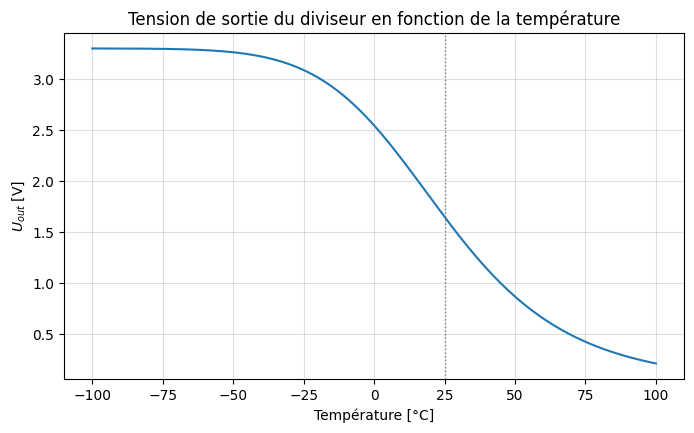

In [73]:
Uout_f = sp.lambdify(T, Uout.subs(Rn, Rntc_T).subs(valeurs), 'numpy')

temperatures_C = np.linspace(-100, 100, 401)
temperatures_K = temperatures_C + T0
U_values = Uout_f(temperatures_K)

plt.figure(figsize=(8, 4.5))
plt.plot(temperatures_C, U_values)
plt.axvline(25, color='gray', ls=':', lw=1)
plt.xlabel('Température [°C]')
plt.ylabel('$U_{out}$ [V]')
plt.title('Tension de sortie du diviseur en fonction de la température')
plt.grid(True, alpha=0.4)
plt.show()

La courbe est une sigmoïde décroissante, quasi linéaire entre 0 et 40 °C environ (pente maximale vers 18 °C). Aux extrêmes, $U_{out}$ sature vers $V_{cc}$ ou vers 0 : la mesure y perd toute sensibilité.

## Relation inverse : température en fonction de la tension mesurée

<IPython.core.display.Math object>

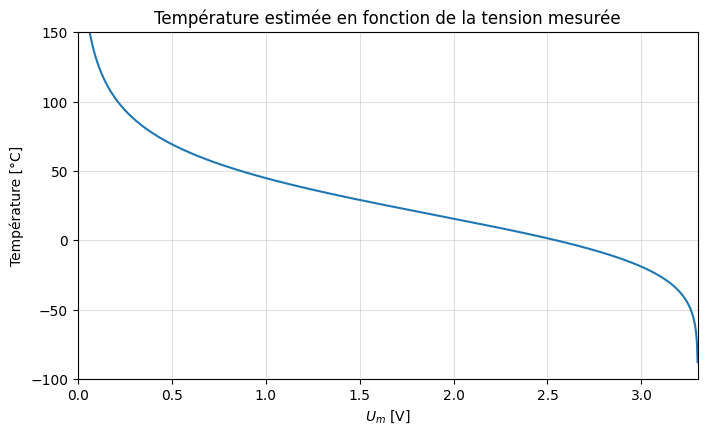

<IPython.core.display.Math object>

In [74]:
Um = sp.Symbol('U_m', positive=True)
T_of_U = sp.solve(sp.Eq(Uout.subs(Rn, Rntc_T), Um), T)[0]
eq('T(U_m)', T_of_U)

T_of_U_f = sp.lambdify(Um, T_of_U.subs(valeurs), 'numpy')
U_grid = np.linspace(1e-3, valeurs[Vcc] - 1e-3, 1000)

plt.figure(figsize=(8, 4.5))
plt.plot(U_grid, T_of_U_f(U_grid) - T0)
plt.xlabel('$U_m$ [V]')
plt.ylabel('Température [°C]')
plt.title('Température estimée en fonction de la tension mesurée')
plt.xlim(0, valeurs[Vcc])
plt.ylim(-100, 150)
plt.grid(True, alpha=0.4)
plt.show()

err = np.max(np.abs(T_of_U_f(U_values) - temperatures_K))
show(r'\max|T(U_{out}(T)) - T|', err, 'K', prefix=False)

## Bruit au point milieu en fonction de la température

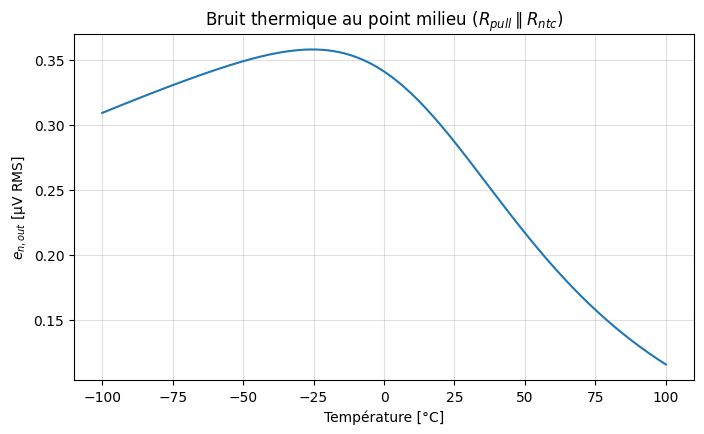

In [75]:
eout_f = sp.lambdify(T, e_out.subs(Rn, Rntc_T).subs(valeurs), 'numpy')
eout_values = eout_f(temperatures_K)

plt.figure(figsize=(8, 4.5))
plt.plot(temperatures_C, eout_values * 1e6)
plt.xlabel('Température [°C]')
plt.ylabel('$e_{n,out}$ [µV RMS]')
plt.title('Bruit thermique au point milieu ($R_{pull} \\parallel R_{ntc}$)')
plt.grid(True, alpha=0.4)
plt.show()

Le bruit dépend peu de la température : $R_{eq}$ reste borné par $R_{pull}$ quand $R_{ntc}$ devient grand (froid), et tend vers 0 quand $R_{ntc}$ devient petit (chaud).

## Sensibilité en fonction de la température

In [76]:
S_T = sp.diff(Uout.subs(Rn, Rntc_T), T)
S_f = sp.lambdify(T, S_T.subs(valeurs), 'numpy')
S_values = S_f(temperatures_K)


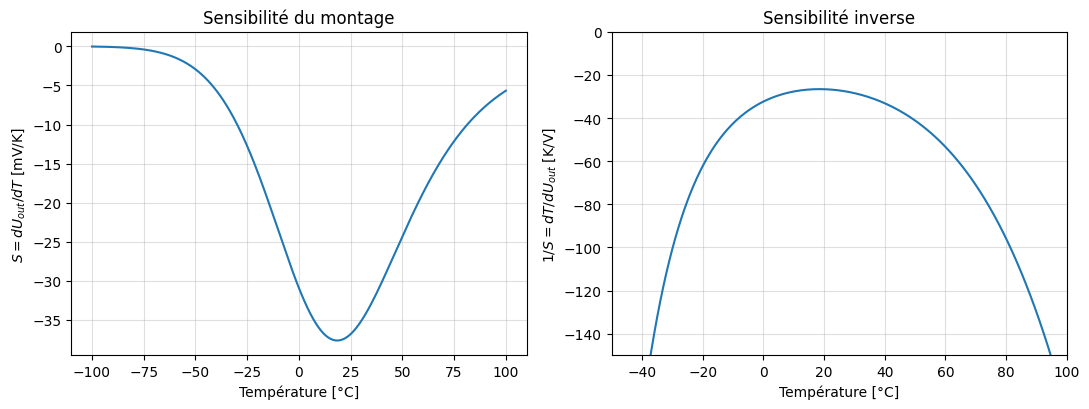

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [77]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(temperatures_C, S_values * 1e3)
ax1.set_xlabel('Température [°C]')
ax1.set_ylabel('$S = dU_{out}/dT$ [mV/K]')
ax1.set_title('Sensibilité du montage')
ax1.grid(True, alpha=0.4)

ax2.plot(temperatures_C, 1 / S_values)
ax2.set_xlabel('Température [°C]')
ax2.set_ylabel('$1/S = dT/dU_{out}$ [K/V]')
ax2.set_title('Sensibilité inverse')
ax2.set_xlim(-50, 100)
ax2.set_ylim(-150, 0)
ax2.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

i_max = np.argmax(np.abs(S_values))
show(r'|S|_{max}', abs(S_values[i_max]), 'V/K')
show(r'T(|S|_{max})', temperatures_C[i_max], r'^\circ C', prefix=False, dec=2)

## Bruit de température en fonction de la température

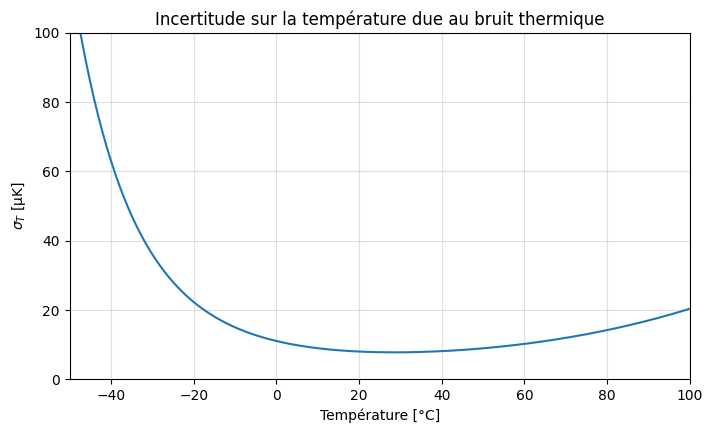

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [78]:
sigma_values = np.abs(eout_values / S_values)

plt.figure(figsize=(8, 4.5))
plt.plot(temperatures_C, sigma_values * 1e6)
plt.xlabel('Température [°C]')
plt.ylabel('$\\sigma_T$ [µK]')
plt.title('Incertitude sur la température due au bruit thermique')
plt.xlim(-50, 100)
plt.ylim(0, 100)
plt.grid(True, alpha=0.4)
plt.show()

i_min = np.argmin(np.where(temperatures_C > -50, sigma_values, np.inf))
show(r'\sigma_{T,min}', sigma_values[i_min], 'K')
show(r'T(\sigma_{T,min})', temperatures_C[i_min], r'^\circ C', prefix=False, dec=2)

L'incertitude due au bruit est minimale vers 28 °C : c'est un compromis entre la sensibilité, maximale vers 18 °C, et le bruit $e_{n,out}$, qui diminue quand la température augmente. Elle remonte fortement aux extrêmes, là où la sensibilité s'effondre, mais reste inférieure à 0.1 mK entre −45 °C et 100 °C : négligeable devant les autres sources d'erreur.

# Que faire pour mesurer à -20°C ?



In [79]:
# Valeurs
T0 = 273.15          # 0 °C en Kelvin
T_C = -20             # point de fonctionnement [°C]

valeurs = {kB: 1.381e-23, dF: 1000, R25: 10e3, T25: 298.15, beta: 3965, Rp: 10e3, Vcc: 3.3}

T_K = T0 + T_C       # point de fonctionnement [K]

A l'instinct, on adapte Rup avec la valeur de R_NTC pour -20°C

In [82]:
Rm20=Rntc_T.subs(valeurs).subs(T, T_K).evalf()
print("Résistance à -20°", Rm20)

Résistance à -20° 106331.389341566


Ajustement dans *valeurs* de la nouvelle valeur pour Rup :

In [88]:
valeurs = {kB: 1.381e-23, dF: 1000, R25: 10e3, T25: 298.15, beta: 3965, Rp: Rm20, Vcc: 3.3}


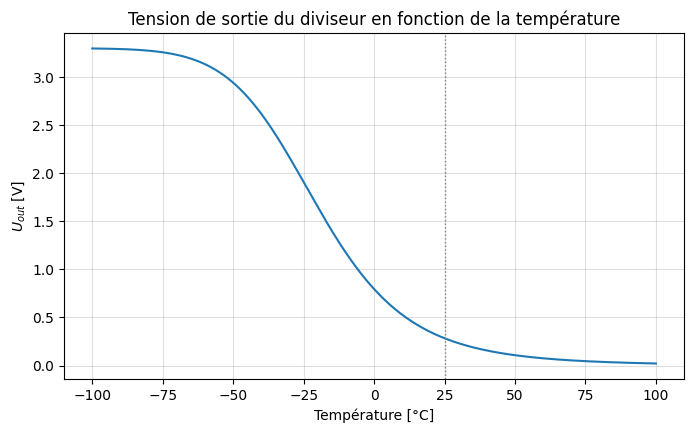

In [87]:
Uout_f = sp.lambdify(T, Uout.subs(Rn, Rntc_T).subs(valeurs), 'numpy')

temperatures_C = np.linspace(-100, 100, 401)
temperatures_K = temperatures_C + T0
U_values = Uout_f(temperatures_K)

plt.figure(figsize=(8, 4.5))
plt.plot(temperatures_C, U_values)
plt.axvline(25, color='gray', ls=':', lw=1)
plt.xlabel('Température [°C]')
plt.ylabel('$U_{out}$ [V]')
plt.title('Tension de sortie du diviseur en fonction de la température')
plt.grid(True, alpha=0.4)
plt.show()

In [84]:
S_T = sp.diff(Uout.subs(Rn, Rntc_T), T)
S_f = sp.lambdify(T, S_T.subs(valeurs), 'numpy')
S_values = S_f(temperatures_K)


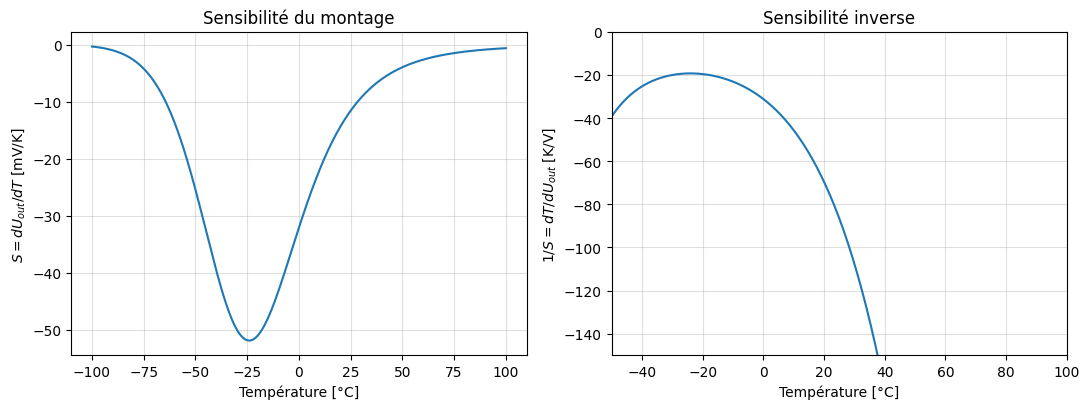

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [86]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(temperatures_C, S_values * 1e3)
ax1.set_xlabel('Température [°C]')
ax1.set_ylabel('$S = dU_{out}/dT$ [mV/K]')
ax1.set_title('Sensibilité du montage')
ax1.grid(True, alpha=0.4)

ax2.plot(temperatures_C, 1 / S_values)
ax2.set_xlabel('Température [°C]')
ax2.set_ylabel('$1/S = dT/dU_{out}$ [K/V]')
ax2.set_title('Sensibilité inverse')
ax2.set_xlim(-50, 100)
ax2.set_ylim(-150, 0)
ax2.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

i_max = np.argmax(np.abs(S_values))
show(r'|S|_{max}', abs(S_values[i_max]), 'V/K')
show(r'T(|S|_{max})', temperatures_C[i_max], r'^\circ C', prefix=False, dec=2)